# Aim 2 feasibility: is the well effect shared across cell types?

**Idea to test.** Every well holds several cell types. A technical well effect (position, evaporation, ambient RNA, handling) should hit all cell types in that well, while a cytokine only acts on cell types with the receptor. If the well effect is partly shared, cell types that do not respond can be used as **internal controls** for the cell types that do.

**Prior evidence.** In OP3 (our Fig. 2B), DMSO-vs-DMSO pseudo-responses from the same well pair correlated across cell types (Spearman about 0.1 to 0.33), and disjoint well pairs did not (about 0).

**Tests in Parse 10M**

| Test | Wells used | Question |
|---|---|---|
| A | 6 PBS wells per donor | Same-well-pair vs disjoint-pair correlation across cell types (Parse copy of Fig. 2B) |
| B | 13 inert cytokine wells per donor (spread over rows) | Same-well vs different-well correlation of well residuals across cell types |
| C | PBS vs inert wells | Is the PBS (row H) shift shared across cell types? |
| D | inert wells | How much of one cell type's well effect can be predicted from the other cell types in the same well? |

All outputs go to `results/cache/aim2_shared_well_effect/`.

In [2]:
import os
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
from scipy.stats import rankdata
import matplotlib.pyplot as plt

DATA_PATH = "data/parse10m/20260203_Parse_10M_PBMC_cytokines.h5ad"
INERT_CSV = "fig1b_inert_size.csv"   # Aim 1 table: cell_type, cytokine, strict, vs_PBS, vs_inert
OUT_DIR = "results/cache/aim2_parse_shared_well_effect"

CHUNK = 200_000      # cells read per chunk when building pseudobulks
MIN_CELLS = 30       # minimum cells per (donor, well, cell type) pseudobulk
N_GENES = 2000       # genes expressed in all cell types, used for all tests
STRICT_ONLY = False  # True: use only receptor-negative ("strict") inert cytokines
SEED = 0

os.makedirs(OUT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

## 1. Cell types

Fine cell types are merged into the six coarse types used in Aim 1. **Check the printed table**: if a fine type is mapped wrongly, edit `to_coarse`. Types mapped to `None` are left out.

In [3]:
a = ad.read_h5ad(DATA_PATH, backed="r")
obs = a.obs[["donor", "bc1_well", "cytokine", "cell_type"]].copy()
for c in obs.columns:
    obs[c] = obs[c].astype(str)


def to_coarse(ct):
    s = ct.replace("_", " ")
    low = s.lower()
    if low.startswith("cd4"):            # CD4 Naive, CD4 Memory (Treg is left out)
        return "CD4 T"
    if low.startswith("cd8"):
        return "CD8 T"
    if low.startswith("b ") or low == "b" or low.startswith("b cell") or low.startswith("b naive") or low.startswith("b memory"):
        return "B"
    if "cd14" in low and "mono" in low:
        return "CD14 Mono"
    if "cd16" in low and "mono" in low:
        return "CD16 Mono"
    if low.startswith("nk") and not low.startswith("nkt") and "bright" not in low:
        return "NK"
    return None


fine_counts = obs.cell_type.value_counts()
mapping = {ct: to_coarse(ct) for ct in fine_counts.index}
print(pd.DataFrame({"n_cells": fine_counts, "coarse": pd.Series(mapping)}).to_string())
obs["ct"] = obs.cell_type.map(mapping)
CELL_TYPES = ["B", "CD4 T", "CD8 T", "CD14 Mono", "CD16 Mono", "NK"]
print("\nCells per coarse type:", obs.ct.value_counts().to_dict())

                       n_cells     coarse
CD4 Memory             2376445      CD4 T
CD4 Naive              1725983      CD4 T
CD14 Mono              1582568  CD14 Mono
CD8 Memory              757585      CD8 T
B Naive                 625239          B
CD8 Naive               619816      CD8 T
NK                      512565         NK
B Intermediate/Memory   326661          B
MAIT                    322923        NaN
CD16 Mono               232755  CD16 Mono
Treg                    168248        NaN
NKT                     158017        NaN
NK CD56bright           125729        NaN
cDC                     112944        NaN
pDC                      18942        NaN
HSPC                     17322        NaN
ILC                       8356        NaN
Plasmablast               5876        NaN

Cells per coarse type: {'CD4 T': 4102428, 'CD14 Mono': 1582568, 'CD8 T': 1377401, 'B': 951900, 'NK': 512565, 'CD16 Mono': 232755}


## 2. Pseudobulk counts per (donor, well, cell type)

Raw counts are summed in chunks, so the 10M-cell file is never loaded into memory. The result is cached and reused on the next run.

In [4]:
PB_PATH = os.path.join(OUT_DIR, "pseudobulk_donor_well_celltype.h5ad")

if os.path.exists(PB_PATH):
    pb = ad.read_h5ad(PB_PATH)
    print("Loaded cached pseudobulk:", pb.shape)
else:
    key = (obs.donor + "|" + obs.bc1_well + "|" + obs.ct.fillna("NA")).where(obs.ct.notna())
    codes, groups = pd.factorize(key)          # cells of unmapped types get code -1
    n_groups = len(groups)
    acc = np.zeros((n_groups, a.n_vars), dtype=np.float32)
    import time
    t0 = time.time()
    for s in range(0, a.n_obs, CHUNK):
        e = min(s + CHUNK, a.n_obs)
        c = codes[s:e]
        m = c >= 0
        if not m.any():
            continue
        X = a.X[s:e]
        X = X if sp.issparse(X) else sp.csr_matrix(X)
        X = X[np.where(m)[0]]
        ug, local = np.unique(c[m], return_inverse=True)
        G = sp.csr_matrix((np.ones(len(local), dtype=np.float32), (local, np.arange(len(local)))),
                          shape=(len(ug), len(local)))
        acc[ug] += np.asarray((G @ X).todense(), dtype=np.float32)
        el = time.time() - t0
        eta = el / e * (a.n_obs - e)
        print(f"  {e:,} / {a.n_obs:,} cells ({e / a.n_obs:.0%}) | elapsed {el / 60:.1f} min | "
              f"remaining ~{eta / 60:.0f} min", flush=True)
    n_cells = np.bincount(codes[codes >= 0], minlength=n_groups)
    meta = pd.DataFrame([g.split("|") for g in groups], columns=["donor", "well", "ct"])
    meta["n_cells"] = n_cells
    well_cyt = obs.drop_duplicates(["donor", "bc1_well"]).set_index(["donor", "bc1_well"]).cytokine
    meta["cytokine"] = [well_cyt[(d, w)] for d, w in zip(meta.donor, meta.well)]
    meta["row"] = meta.well.str[0]
    meta["col"] = meta.well.str[1:].astype(int)
    meta.index = [f"g{i}" for i in range(n_groups)]
    pb = ad.AnnData(X=sp.csr_matrix(acc), obs=meta, var=pd.DataFrame(index=a.var_names.astype(str)))
    pb.write_h5ad(PB_PATH)
    print(f"Saved {PB_PATH} {pb.shape} | total {(time.time() - t0) / 60:.1f} min")

a.file.close()
meta = pb.obs.copy()
meta = meta[meta.ct.isin(CELL_TYPES)]
print(meta.groupby("ct").n_cells.describe()[["min", "50%", "max"]])

Loaded cached pseudobulk: (6910, 40352)
             min     50%      max
ct                               
B           52.0   680.0   3919.0
CD4 T      408.0  3228.0  15267.0
CD8 T      157.0  1163.0   3522.0
CD14 Mono  100.0  1247.5   5922.0
CD16 Mono    2.0   197.5    726.0
NK          46.0   392.0   1726.0


## 3. Normalisation, genes and well groups

- log2(CPM + 1) per pseudobulk.
- Genes: the `N_GENES` genes with the highest **minimum** mean CPM across the six cell types, so the same genes are compared in every cell type.
- Inert cytokines come from the Aim 1 table.

In [5]:
counts = pb[meta.index].X
counts = counts.toarray() if sp.issparse(counts) else np.asarray(counts)
lib = counts.sum(1, keepdims=True)
cpm = counts / np.maximum(lib, 1) * 1e6

ok = (meta.n_cells.values >= MIN_CELLS)
mean_by_ct = np.vstack([cpm[ok & (meta.ct.values == ct)].mean(0) for ct in CELL_TYPES])
min_mean = mean_by_ct.min(0)
genes = np.argsort(-min_mean)[:N_GENES]
L = np.log2(cpm[:, genes] + 1).astype(np.float32)
print(f"Genes used: {len(genes)} | min of mean CPM among them: {min_mean[genes].min():.1f}")

meta = meta.assign(ok=ok, i=np.arange(len(meta)))
idx = {(d, w, c): i for d, w, c, i in zip(meta.donor, meta.well, meta.ct, meta.i)}

inert_tab = pd.read_csv(INERT_CSV)
if STRICT_ONLY:
    inert_tab = inert_tab[inert_tab.strict]
inert_by_ct = inert_tab.groupby("cell_type").cytokine.apply(set).to_dict()
INERT = set.intersection(*[inert_by_ct.get(ct, set()) for ct in CELL_TYPES])
present = set(meta.cytokine.unique())
print("Inert cytokines used in all cell types:", sorted(INERT))
print("Not found in data:", sorted(INERT - present))
INERT &= present

donors = sorted(meta.donor.unique())
wells_of = {d: meta[meta.donor == d].drop_duplicates("well").set_index("well").cytokine for d in donors}
PBS_WELLS = {d: sorted(w for w, c in wells_of[d].items() if c == "PBS") for d in donors}
INERT_WELLS = {d: sorted(w for w, c in wells_of[d].items() if c in INERT) for d in donors}
print("PBS wells (first donor):", PBS_WELLS[donors[0]])
print("Inert wells (first donor):", INERT_WELLS[donors[0]])


def vec(d, w, ct):
    i = idx.get((d, w, ct))
    if i is None or not meta.ok.values[i]:
        return None
    return L[i]


def spear(x, y):
    return np.corrcoef(rankdata(x), rankdata(y))[0, 1]


CT_PAIRS = [(c1, c2) for k, c1 in enumerate(CELL_TYPES) for c2 in CELL_TYPES[k + 1:]]

Genes used: 2000 | min of mean CPM among them: 61.8
Inert cytokines used in all cell types: ['Decorin', 'EGF', 'EPO', 'FGF-beta', 'GDNF', 'HGF', 'IGF-1', 'Megalin', 'Noggin', 'PRL', 'PSPN', 'TPO', 'VEGF']
Not found in data: []
PBS wells (first donor): ['H10', 'H11', 'H12', 'H7', 'H8', 'H9']
Inert wells (first donor): ['E10', 'E11', 'E12', 'E4', 'E9', 'F1', 'F10', 'F2', 'F3', 'F4', 'F7', 'F8', 'G1']


## 4. Test A: PBS-vs-PBS pseudo-responses (Parse copy of Fig. 2B)

For two PBS wells w1, w2 of the same donor, the pseudo-response in cell type c is `L(w1, c) - L(w2, c)`. PBS vs PBS has no biology, so it holds only noise and well effects. Cells of different types are different cells, so sampling noise is independent between cell types. A correlation between cell types therefore points to a shared well effect.

In [6]:
rows = []
for d in donors:
    W = PBS_WELLS[d]
    pairs = [(W[i], W[j]) for i in range(len(W)) for j in range(i + 1, len(W))]
    diff = {}
    for p in pairs:
        for ct in CELL_TYPES:
            v1, v2 = vec(d, p[0], ct), vec(d, p[1], ct)
            if v1 is not None and v2 is not None:
                diff[(p, ct)] = v1 - v2
    for c1, c2 in CT_PAIRS:
        for p in pairs:
            if (p, c1) in diff and (p, c2) in diff:
                rows.append(dict(donor=d, pair=f"{c1} / {c2}", kind="same well pair",
                                 rho=spear(diff[(p, c1)], diff[(p, c2)])))
            for q in pairs:
                if set(p) & set(q) or q <= p:
                    continue
                if (p, c1) in diff and (q, c2) in diff:
                    rows.append(dict(donor=d, pair=f"{c1} / {c2}", kind="disjoint well pairs",
                                     rho=spear(diff[(p, c1)], diff[(q, c2)])))
testA = pd.DataFrame(rows)
testA_donor = testA.groupby(["pair", "kind", "donor"]).rho.median().reset_index()
testA_sum = testA_donor.groupby(["pair", "kind"]).rho.median().unstack()
testA.to_csv(os.path.join(OUT_DIR, "testA_pbs_pairs.csv"), index=False)
print(testA_sum.round(3).to_string())
print("\nOverall median: same =", round(testA_donor[testA_donor.kind == "same well pair"].rho.median(), 3),
      "| disjoint =", round(testA_donor[testA_donor.kind == "disjoint well pairs"].rho.median(), 3))

kind                   disjoint well pairs  same well pair
pair                                                      
B / CD14 Mono                       -0.008           0.425
B / CD16 Mono                        0.005           0.297
B / CD4 T                            0.009           0.465
B / CD8 T                            0.001           0.409
B / NK                               0.004           0.334
CD14 Mono / CD16 Mono                0.033           0.465
CD14 Mono / NK                       0.019           0.358
CD16 Mono / NK                       0.011           0.272
CD4 T / CD14 Mono                    0.018           0.527
CD4 T / CD16 Mono                    0.019           0.372
CD4 T / CD8 T                        0.038           0.610
CD4 T / NK                           0.020           0.427
CD8 T / CD14 Mono                    0.021           0.448
CD8 T / CD16 Mono                    0.015           0.314
CD8 T / NK                           0.021           0.3

## 5. Test B: residuals of inert wells across rows

Inert cytokine wells are spread over many rows. For each donor and cell type, the residual of a well is its profile minus the mean of that donor's inert wells. If the well effect is shared, residuals of the **same well** should correlate between cell types, and residuals of **different wells** should not.

In [7]:
def inert_residuals(d, ct):
    W = [w for w in INERT_WELLS[d] if vec(d, w, ct) is not None]
    if len(W) < 4:
        return {}
    M = np.vstack([vec(d, w, ct) for w in W])
    R = M - M.mean(0)
    return dict(zip(W, R))


RES = {(d, ct): inert_residuals(d, ct) for d in donors for ct in CELL_TYPES}

rows = []
for d in donors:
    for c1, c2 in CT_PAIRS:
        r1, r2 = RES[(d, c1)], RES[(d, c2)]
        common = sorted(set(r1) & set(r2))
        for w in common:
            rows.append(dict(donor=d, pair=f"{c1} / {c2}", kind="same well", rho=spear(r1[w], r2[w])))
            others = [x for x in common if x != w]
            for w2 in rng.choice(others, size=min(3, len(others)), replace=False):
                rows.append(dict(donor=d, pair=f"{c1} / {c2}", kind="different well", rho=spear(r1[w], r2[w2])))
testB = pd.DataFrame(rows)
testB_donor = testB.groupby(["pair", "kind", "donor"]).rho.median().reset_index()
testB_sum = testB_donor.groupby(["pair", "kind"]).rho.median().unstack()
testB.to_csv(os.path.join(OUT_DIR, "testB_inert_residuals.csv"), index=False)
print(testB_sum.round(3).to_string())
print("\nOverall median: same =", round(testB_donor[testB_donor.kind == "same well"].rho.median(), 3),
      "| different =", round(testB_donor[testB_donor.kind == "different well"].rho.median(), 3))
print("(Different-well values are slightly negative by construction, because the mean is subtracted.)")

kind                   different well  same well
pair                                            
B / CD14 Mono                  -0.021      0.421
B / CD16 Mono                  -0.029      0.320
B / CD4 T                      -0.027      0.473
B / CD8 T                      -0.026      0.417
B / NK                         -0.025      0.325
CD14 Mono / CD16 Mono          -0.037      0.388
CD14 Mono / NK                 -0.027      0.344
CD16 Mono / NK                 -0.008      0.229
CD4 T / CD14 Mono              -0.019      0.509
CD4 T / CD16 Mono              -0.038      0.353
CD4 T / CD8 T                  -0.030      0.589
CD4 T / NK                     -0.028      0.375
CD8 T / CD14 Mono              -0.036      0.434
CD8 T / CD16 Mono              -0.034      0.300
CD8 T / NK                     -0.036      0.349

Overall median: same = 0.387 | different = -0.028
(Different-well values are slightly negative by construction, because the mean is subtracted.)


## 6. Test C: is the PBS (row H) shift shared across cell types?

Shift = mean of PBS wells minus mean of inert wells, per donor and cell type. We compare the cosine of this shift between cell types with a **noise-only shift**: inert wells split at random into two groups of the same sizes (6 vs the rest).

Note: a shared shift is consistent with a technical well/position effect, but also with a generic effect of adding protein to the medium. This test cannot separate the two (same limitation as in Aim 1).

In [8]:
def cos(x, y):
    return float(x @ y / (np.linalg.norm(x) * np.linalg.norm(y) + 1e-12))


rows = []
for d in donors:
    shift, fake = {}, {}
    for ct in CELL_TYPES:
        P = [vec(d, w, ct) for w in PBS_WELLS[d]]
        I = [vec(d, w, ct) for w in INERT_WELLS[d]]
        P = [v for v in P if v is not None]
        I = [v for v in I if v is not None]
        if len(P) < 3 or len(I) < 8:
            continue
        shift[ct] = np.mean(P, 0) - np.mean(I, 0)
        perm = rng.permutation(len(I))
        k = min(len(P), len(I) // 2)
        fake[ct] = np.mean([I[j] for j in perm[:k]], 0) - np.mean([I[j] for j in perm[k:]], 0)
    for c1, c2 in CT_PAIRS:
        if c1 in shift and c2 in shift:
            rows.append(dict(donor=d, pair=f"{c1} / {c2}", kind="PBS - inert", cos=cos(shift[c1], shift[c2])))
            rows.append(dict(donor=d, pair=f"{c1} / {c2}", kind="noise-only", cos=cos(fake[c1], fake[c2])))
testC = pd.DataFrame(rows)
testC_sum = testC.groupby(["pair", "kind"]).cos.median().unstack()
testC.to_csv(os.path.join(OUT_DIR, "testC_pbs_shift.csv"), index=False)
print(testC_sum.round(3).to_string())

kind                   PBS - inert  noise-only
pair                                          
B / CD14 Mono                0.508       0.011
B / CD16 Mono                0.404      -0.013
B / CD4 T                    0.608      -0.072
B / CD8 T                    0.532       0.032
B / NK                       0.469       0.095
CD14 Mono / CD16 Mono        0.539      -0.038
CD14 Mono / NK               0.437      -0.226
CD16 Mono / NK               0.369      -0.003
CD4 T / CD14 Mono            0.601      -0.060
CD4 T / CD16 Mono            0.463      -0.042
CD4 T / CD8 T                0.727       0.296
CD4 T / NK                   0.526       0.108
CD8 T / CD14 Mono            0.545       0.008
CD8 T / CD16 Mono            0.429       0.047
CD8 T / NK                   0.508      -0.072


## 7. Test D: can the other cell types predict one cell type's well effect?

This is the number that matters for the model. For a target cell type, the predictor is the mean inert-well residual of the **other** cell types in the **same well**. For each gene, a slope is fitted on half of the wells and tested on the other half. We report R² (share of the target's well-residual variance explained, summed over genes), against a null where the predictor comes from a **different well** of the same donor.

In [9]:
def build_xy(ct, shuffle=False):
    X, Y, unit = [], [], []
    for d in donors:
        tgt = RES[(d, ct)]
        oth = [RES[(d, c)] for c in CELL_TYPES if c != ct]
        W = [w for w in tgt if all(w in o for o in oth)]
        if len(W) < 4:
            continue
        src = list(rng.permutation(W)) if shuffle else W
        for w, ws in zip(W, src):
            if shuffle and ws == w:
                ws = W[(W.index(w) + 1) % len(W)]
            Y.append(tgt[w])
            X.append(np.mean([o[ws] for o in oth], 0))
            unit.append(f"{d}|{w}")
    return np.array(X), np.array(Y), np.array(unit)


def r2_split(X, Y, n_rep=20):
    out = []
    for _ in range(n_rep):
        tr = rng.random(len(Y)) < 0.5
        te = ~tr
        b = (X[tr] * Y[tr]).sum(0) / np.maximum((X[tr] ** 2).sum(0), 1e-12)   # one slope per gene
        pred = X[te] * b
        out.append(1 - ((Y[te] - pred) ** 2).sum() / (Y[te] ** 2).sum())
    return float(np.median(out))


rows = []
for ct in CELL_TYPES:
    X, Y, _ = build_xy(ct)
    if len(Y) < 10:
        continue
    r2 = r2_split(X, Y)
    null = [r2_split(*build_xy(ct, shuffle=True)[:2], n_rep=5) for _ in range(10)]
    rows.append(dict(cell_type=ct, n_wells=len(Y), R2_same_well=r2,
                     R2_null_median=float(np.median(null)), R2_null_max=float(np.max(null))))
testD = pd.DataFrame(rows)
testD.to_csv(os.path.join(OUT_DIR, "testD_predict_well_effect.csv"), index=False)
print(testD.round(3).to_string(index=False))

cell_type  n_wells  R2_same_well  R2_null_median  R2_null_max
        B      142         0.437          -0.014       -0.006
    CD4 T      142         0.678          -0.013       -0.004
    CD8 T      142         0.560          -0.012        0.013
CD14 Mono      142         0.531          -0.008       -0.001
CD16 Mono      142         0.268          -0.013       -0.003
       NK      142         0.349          -0.012       -0.001


## 8. Figure and verdict

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_parse_shared_well_effect/aim2_shared_well_effect.png True
Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_parse_shared_well_effect/aim2_shared_well_effect.pdf True


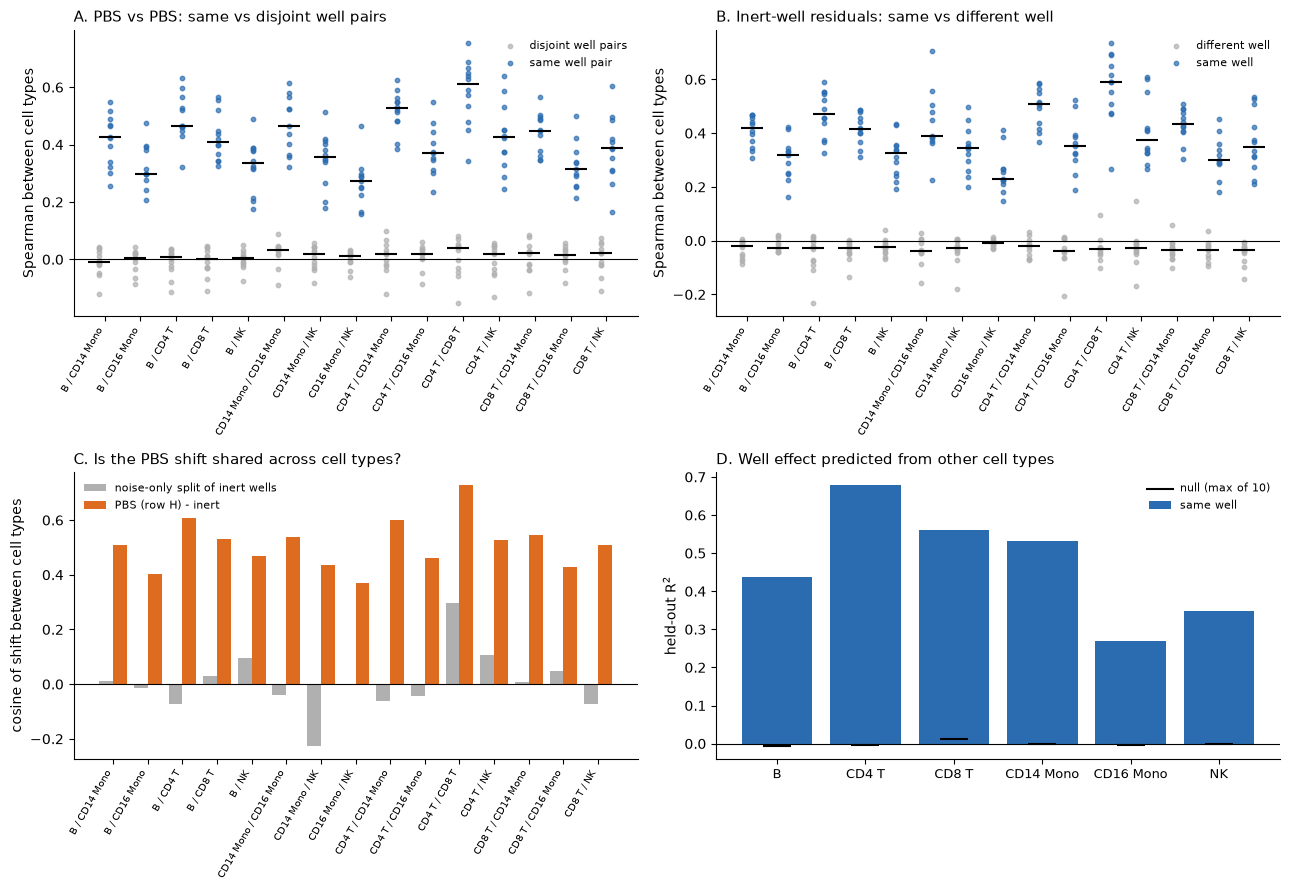

                         test  same  control  passes
                 A: PBS pairs 0.399    0.016    True
           B: inert residuals 0.387   -0.028    True
D: R² above null (cell types) 0.487    0.000    True

If A, B and D pass: the shared well effect is real in Parse and Novelty 1 is feasible.
If A and B pass but D is small: the effect is shared but weak; the model needs a cell-type-specific loading.
If A and B fail: the well effect is mostly cell-type specific; drop Novelty 1.


In [10]:
COL = {"same": "#2b6cb0", "ctrl": "#b0b0b0", "pbs": "#dd6b20"}
pairs = sorted(testA_donor.pair.unique())
x = np.arange(len(pairs))

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax = ax.ravel()

# A and B: one point per donor, same-well vs control
for k, (tab, same, ctrl, title) in enumerate([
        (testA_donor, "same well pair", "disjoint well pairs", "A. PBS vs PBS: same vs disjoint well pairs"),
        (testB_donor, "same well", "different well", "B. Inert-well residuals: same vs different well")]):
    for kind, color, off in [(ctrl, COL["ctrl"], -0.15), (same, COL["same"], 0.15)]:
        sub = tab[tab.kind == kind]
        ax[k].scatter([pairs.index(p) + off for p in sub.pair], sub.rho, s=10, alpha=0.7, color=color, label=kind)
        med = sub.groupby("pair").rho.median().reindex(pairs)
        ax[k].scatter(x + off, med, marker="_", s=250, color="k", lw=1.5)
    ax[k].axhline(0, color="k", lw=0.8)
    ax[k].set_ylabel("Spearman between cell types")
    ax[k].set_title(title, loc="left", fontsize=11)
    ax[k].legend(fontsize=8, frameon=False)

# C: PBS shift cosine vs noise-only shift
cmed = testC.groupby(["pair", "kind"]).cos.median().unstack().reindex(pairs)
ax[2].bar(x - 0.2, cmed["noise-only"], 0.4, color=COL["ctrl"], label="noise-only split of inert wells")
ax[2].bar(x + 0.2, cmed["PBS - inert"], 0.4, color=COL["pbs"], label="PBS (row H) - inert")
ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_ylabel("cosine of shift between cell types")
ax[2].set_title("C. Is the PBS shift shared across cell types?", loc="left", fontsize=11)
ax[2].legend(fontsize=8, frameon=False)

for k in range(3):
    ax[k].set_xticks(x)
    ax[k].set_xticklabels(pairs, rotation=60, ha="right", fontsize=7)

# D: R2 of a cell type's well effect predicted from the other cell types
ax[3].bar(testD.cell_type, testD.R2_same_well, color=COL["same"], label="same well")
ax[3].scatter(testD.cell_type, testD.R2_null_max, color="k", marker="_", s=400, label="null (max of 10)")
ax[3].axhline(0, color="k", lw=0.8)
ax[3].set_ylabel("held-out R$^2$")
ax[3].set_title("D. Well effect predicted from other cell types", loc="left", fontsize=11)
ax[3].legend(fontsize=8, frameon=False)
ax[3].tick_params(axis="x", labelsize=9)

for a_ in ax:
    a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

fig_png = os.path.abspath(os.path.join(OUT_DIR, "aim2_shared_well_effect.png"))
fig_pdf = fig_png.replace(".png", ".pdf")
fig.savefig(fig_png, dpi=200, bbox_inches="tight")
fig.savefig(fig_pdf, bbox_inches="tight")
print("Saved:", fig_png, os.path.exists(fig_png))
print("Saved:", fig_pdf, os.path.exists(fig_pdf))
plt.show()

a_same = testA_donor[testA_donor.kind == "same well pair"].rho.median()
a_dis = testA_donor[testA_donor.kind == "disjoint well pairs"].rho.median()
b_same = testB_donor[testB_donor.kind == "same well"].rho.median()
b_dif = testB_donor[testB_donor.kind == "different well"].rho.median()
d_gain = (testD.R2_same_well - testD.R2_null_max)
verdict = pd.DataFrame([
    dict(test="A: PBS pairs", same=a_same, control=a_dis, passes=(a_same - a_dis) > 0.05),
    dict(test="B: inert residuals", same=b_same, control=b_dif, passes=(b_same - b_dif) > 0.05),
    dict(test="D: R² above null (cell types)", same=float(d_gain.median()), control=0.0,
         passes=bool((d_gain > 0).sum() >= 4)),
])
verdict.to_csv(os.path.join(OUT_DIR, "verdict.csv"), index=False)
print(verdict.round(3).to_string(index=False))
print("\nIf A, B and D pass: the shared well effect is real in Parse and Novelty 1 is feasible.")
print("If A and B pass but D is small: the effect is shared but weak; the model needs a cell-type-specific loading.")
print("If A and B fail: the well effect is mostly cell-type specific; drop Novelty 1.")

## 9. Robustness checks for Test D

1. **Is the shared part technical, or a small real effect of some "inert" cytokine?**
   - Repeat Test D with only the **strict** inert set (receptor-negative cytokines).
   - **Leave one inert cytokine out** at a time. If one cytokine drives the result, R² drops when it is removed.
2. **Is it just similar biology between related cell types (e.g. CD4 T and CD8 T)?**
   - Predict **lymphoid** cell types only from **myeloid** ones, and the reverse.

If R² stays well above the null in all checks, the shared well effect is not explained by one cytokine or by related cell types.

In [11]:
LYMPHOID = ["B", "CD4 T", "CD8 T", "NK"]
MYELOID = ["CD14 Mono", "CD16 Mono"]


def residuals_for(inert_set):
    """Inert-well residuals per (donor, cell type), using only the given inert cytokines."""
    out = {}
    for d in donors:
        W_all = [w for w, c in wells_of[d].items() if c in inert_set]
        for ct in CELL_TYPES:
            W = [w for w in W_all if vec(d, w, ct) is not None]
            if len(W) < 4:
                out[(d, ct)] = {}
                continue
            M = np.vstack([vec(d, w, ct) for w in W])
            out[(d, ct)] = dict(zip(W, M - M.mean(0)))
    return out


def xy_from(res, ct, predictors, shuffle=False):
    X, Y = [], []
    for d in donors:
        tgt = res[(d, ct)]
        oth = [res[(d, c)] for c in predictors]
        W = [w for w in tgt if all(w in o for o in oth)]
        if len(W) < 4:
            continue
        src = list(rng.permutation(W)) if shuffle else W
        for w, ws in zip(W, src):
            if shuffle and ws == w:
                ws = W[(W.index(w) + 1) % len(W)]
            Y.append(tgt[w])
            X.append(np.mean([o[ws] for o in oth], 0))
    return np.array(X), np.array(Y)


def r2_with_null(res, ct, predictors, n_null=10):
    X, Y = xy_from(res, ct, predictors)
    if len(Y) < 10:
        return np.nan, np.nan, len(Y)
    r2 = r2_split(X, Y)
    null = [r2_split(*xy_from(res, ct, predictors, shuffle=True), n_rep=5) for _ in range(n_null)]
    return r2, float(np.max(null)), len(Y)


rows = []
# Baseline (all inert, all other cell types) for reference
RES_ALL = residuals_for(INERT)
for ct in CELL_TYPES:
    r2, nmax, n = r2_with_null(RES_ALL, ct, [c for c in CELL_TYPES if c != ct])
    rows.append(dict(check="all inert, other cell types", cell_type=ct, n_wells=n, R2=r2, null_max=nmax))

# Check 1a: strict inert only
STRICT = set(inert_tab[inert_tab.strict].groupby("cell_type").cytokine.apply(set).pipe(
    lambda s: set.intersection(*[s.get(ct, set()) for ct in CELL_TYPES]))) & present
print("Strict inert set:", sorted(STRICT))
RES_STRICT = residuals_for(STRICT)
for ct in CELL_TYPES:
    r2, nmax, n = r2_with_null(RES_STRICT, ct, [c for c in CELL_TYPES if c != ct])
    rows.append(dict(check="strict inert only", cell_type=ct, n_wells=n, R2=r2, null_max=nmax))

# Check 2: distant lineages only
for ct in CELL_TYPES:
    preds = MYELOID if ct in LYMPHOID else LYMPHOID
    r2, nmax, n = r2_with_null(RES_ALL, ct, preds)
    rows.append(dict(check="other lineage only", cell_type=ct, n_wells=n, R2=r2, null_max=nmax))

robust = pd.DataFrame(rows)
robust.to_csv(os.path.join(OUT_DIR, "testD_robustness.csv"), index=False)
print(robust.pivot(index="cell_type", columns="check", values="R2").reindex(CELL_TYPES).round(3).to_string())
print("\nMax null R2 over all checks:", round(robust.null_max.max(), 3))

Strict inert set: ['EGF', 'EPO', 'Megalin', 'PSPN', 'TPO']
check      all inert, other cell types  other lineage only  strict inert only
cell_type                                                                    
B                                0.442               0.354              0.358
CD4 T                            0.678               0.521              0.619
CD8 T                            0.560               0.419              0.498
CD14 Mono                        0.539               0.470              0.480
CD16 Mono                        0.271               0.228              0.196
NK                               0.352               0.255              0.288

Max null R2 over all checks: 0.08


In [12]:
# Check 1b: leave one inert cytokine out
rows = []
for cyt in sorted(INERT):
    res = residuals_for(INERT - {cyt})
    for ct in CELL_TYPES:
        X, Y = xy_from(res, ct, [c for c in CELL_TYPES if c != ct])
        rows.append(dict(left_out=cyt, cell_type=ct, R2=r2_split(X, Y, n_rep=10)))
loo = pd.DataFrame(rows)
loo.to_csv(os.path.join(OUT_DIR, "testD_leave_one_cytokine_out.csv"), index=False)
tab = loo.pivot(index="left_out", columns="cell_type", values="R2")[CELL_TYPES]
base = robust[robust.check == "all inert, other cell types"].set_index("cell_type").R2
print(tab.round(3).to_string())
print("\nLargest drop from baseline when one cytokine is removed:")
print((base - tab.min()).round(3).to_string())

cell_type      B  CD4 T  CD8 T  CD14 Mono  CD16 Mono     NK
left_out                                                   
Decorin    0.422  0.677  0.552      0.526      0.265  0.340
EGF        0.442  0.693  0.555      0.535      0.266  0.361
EPO        0.435  0.685  0.563      0.539      0.278  0.349
FGF-beta   0.426  0.678  0.531      0.521      0.260  0.323
GDNF       0.438  0.679  0.564      0.538      0.265  0.356
HGF        0.461  0.713  0.555      0.550      0.287  0.344
IGF-1      0.421  0.666  0.552      0.529      0.259  0.327
Megalin    0.449  0.664  0.549      0.528      0.275  0.349
Noggin     0.421  0.653  0.542      0.526      0.245  0.330
PRL        0.437  0.697  0.561      0.543      0.272  0.361
PSPN       0.436  0.674  0.570      0.529      0.279  0.330
TPO        0.433  0.692  0.556      0.540      0.272  0.344
VEGF       0.437  0.677  0.564      0.545      0.269  0.349

Largest drop from baseline when one cytokine is removed:
cell_type
B            0.021
CD4 T        

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_parse_shared_well_effect/aim2_testD_robustness.png True


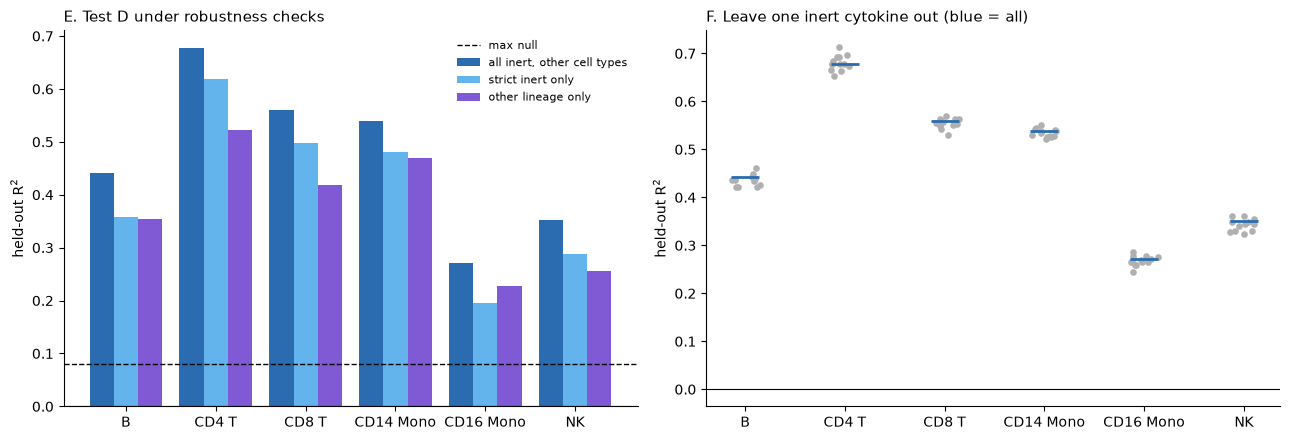

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
piv = robust.pivot(index="cell_type", columns="check", values="R2").reindex(CELL_TYPES)
order = ["all inert, other cell types", "strict inert only", "other lineage only"]
colors = ["#2b6cb0", "#63b3ed", "#805ad5"]
xx = np.arange(len(CELL_TYPES))
for k, (c, col) in enumerate(zip(order, colors)):
    ax[0].bar(xx + (k - 1) * 0.27, piv[c], 0.27, color=col, label=c)
ax[0].axhline(robust.null_max.max(), color="k", ls="--", lw=1, label="max null")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xticks(xx)
ax[0].set_xticklabels(CELL_TYPES)
ax[0].set_ylabel("held-out R$^2$")
ax[0].set_title("E. Test D under robustness checks", loc="left", fontsize=11)
ax[0].legend(fontsize=8, frameon=False)

for j, ct in enumerate(CELL_TYPES):
    v = tab[ct].values
    ax[1].scatter(np.full(len(v), j) + rng.uniform(-0.15, 0.15, len(v)), v, s=14, color="#b0b0b0")
    ax[1].scatter(j, base[ct], marker="_", s=400, color="#2b6cb0", lw=2)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xticks(xx)
ax[1].set_xticklabels(CELL_TYPES)
ax[1].set_ylabel("held-out R$^2$")
ax[1].set_title("F. Leave one inert cytokine out (blue = all)", loc="left", fontsize=11)
for a_ in ax:
    a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
p_png = os.path.abspath(os.path.join(OUT_DIR, "aim2_testD_robustness.png"))
fig.savefig(p_png, dpi=200, bbox_inches="tight")
fig.savefig(p_png.replace(".png", ".pdf"), bbox_inches="tight")
print("Saved:", p_png, os.path.exists(p_png))
plt.show()

## 8. Ambient RNA check
If the shared well effect were ambient RNA, it would lie on the axis "well soup minus the cell line's own profile" (genes the other lines express and this line lacks), its size per well would agree across lines, and it would be larger in lines with fewer UMIs per cell. Decisive test: remove that axis and recompute the same-well correlation.

In [14]:
N_LINE_PAIRS = 400
rng = np.random.default_rng(0)
from scipy.stats import spearmanr
N_AMB_GENES = 5000

def ambient_axis(D, line_cpm, pool_cpm):
    """D: [units, lines, genes] residuals. Returns per-unit ambient coefficient, share of variance, axis."""
    X = np.log2(pool_cpm + 1)[None, :] - np.log2(line_cpm + 1)
    X = X - X.mean(1, keepdims=True)
    U, Lc, _ = D.shape
    beta = np.full((U, Lc), np.nan)
    num, den = np.zeros(Lc), np.zeros(Lc)
    for l in range(Lc):
        x = X[l]; xx = x @ x
        for u in range(U):
            d = D[u, l]
            if np.isnan(d).any():
                continue
            d = d - d.mean()
            b = (d @ x) / xx
            beta[u, l] = b
            num[l] += b * b * xx
            den[l] += d @ d
    return beta, num / np.maximum(den, 1e-12), X

def remove_ambient(D, beta, X):
    return D - np.nan_to_num(beta)[:, :, None] * X[None, :, :]

def beta_consistency(beta, n_pairs=N_LINE_PAIRS):
    out = []
    for _ in range(n_pairs):
        a, b = rng.choice(beta.shape[1], 2, replace=False)
        m = np.where(~np.isnan(beta[:, a]) & ~np.isnan(beta[:, b]))[0]
        if len(m) < 10:
            continue
        out.append((spearmanr(beta[m, a], beta[m, b])[0],
                    spearmanr(beta[m, a], beta[rng.permutation(m), b])[0]))
    return pd.DataFrame(out, columns=["same unit", "shuffled units"])

def sample_pairs(D, n_pairs=N_LINE_PAIRS * 3):
    U, Lc, _ = D.shape
    P = []
    while len(P) < n_pairs:
        u = rng.integers(U); a, b = rng.choice(Lc, 2, replace=False)
        if not (np.isnan(D[u, a, 0]) or np.isnan(D[u, b, 0])):
            P.append((u, a, b))
    return P

def same_unit_corrs(D, pairs):
    return np.array([spearmanr(D[u, a], D[u, b])[0] for u, a, b in pairs])

In [15]:
import time
t0 = time.time()
pbP = ad.read_h5ad(os.path.join(OUT_DIR, "pseudobulk_donor_well_celltype.h5ad"))
o = pbP.obs.copy()
print("obs columns:", o.columns.tolist())
pick = lambda cands: next(c for c in cands if c in o.columns)
DON, WEL = pick(["donor"]), pick(["well", "bc1_well"])
CYT, CT = pick(["cytokine"]), pick(["ct", "cell_type", "coarse", "celltype"])

inert = set(INERT)        # same inert set as Tests B and D (already intersected with the data)
use = o[CYT].astype(str).isin(inert | {"PBS"}).values
print("Inert + PBS rows:", use.sum())

tot = np.asarray(pbP.X.sum(0)).ravel()
gidx = np.argsort(tot)[::-1][:N_AMB_GENES]
X = pbP.X[:, gidx]
X = X.toarray() if sp.issparse(X) else np.asarray(X)
lib = np.asarray(pbP.X.sum(1)).ravel()

NAMES = list(CELL_TYPES)
ci = {c: i for i, c in enumerate(NAMES)}
units = sorted(set(zip(o.loc[use, DON].astype(str), o.loc[use, WEL].astype(str))))
ui = {u: i for i, u in enumerate(units)}

T = np.full((len(units), len(NAMES), len(gidx)), np.nan, np.float32)
raw = np.zeros((len(NAMES), len(gidx)))
cells, libs = np.zeros(len(NAMES)), np.zeros(len(NAMES))
for k in range(len(o)):
    ct_k = str(o[CT].iat[k])
    if ct_k not in ci:
        continue
    c = ci[ct_k]
    raw[c] += X[k]; cells[c] += o.n_cells.iat[k]; libs[c] += lib[k]
    if use[k] and o.n_cells.iat[k] >= MIN_CELLS:
        T[ui[(str(o[DON].iat[k]), str(o[WEL].iat[k]))], c] = np.log2(X[k] / lib[k] * 1e6 + 1)

# residual: subtract each donor's mean over its inert + PBS wells, per cell type
D = T.copy()
donors_u = np.array([u[0] for u in units])
for d in np.unique(donors_u):
    m = donors_u == d
    D[m] = D[m] - np.nanmean(D[m], axis=0, keepdims=True)
line_cpm = raw / raw.sum(1, keepdims=True) * 1e6
pool_cpm = raw.sum(0) / raw.sum() * 1e6
umi = libs / cells
TAG, UNIT = "parse", "donor-well"
print(f"D: {D.shape} | cell types: {NAMES} | {time.time() - t0:.0f}s")

obs columns: ['donor', 'well', 'ct', 'n_cells', 'cytokine', 'row', 'col']
Inert + PBS rows: 1368
D: (228, 6, 5000) | cell types: ['B', 'CD4 T', 'CD8 T', 'CD14 Mono', 'CD16 Mono', 'NK'] | 2s


/tmp/ipykernel_541675/775905800.py:42: RuntimeWarning: Mean of empty slice
  D[m] = D[m] - np.nanmean(D[m], axis=0, keepdims=True)


done | 2s


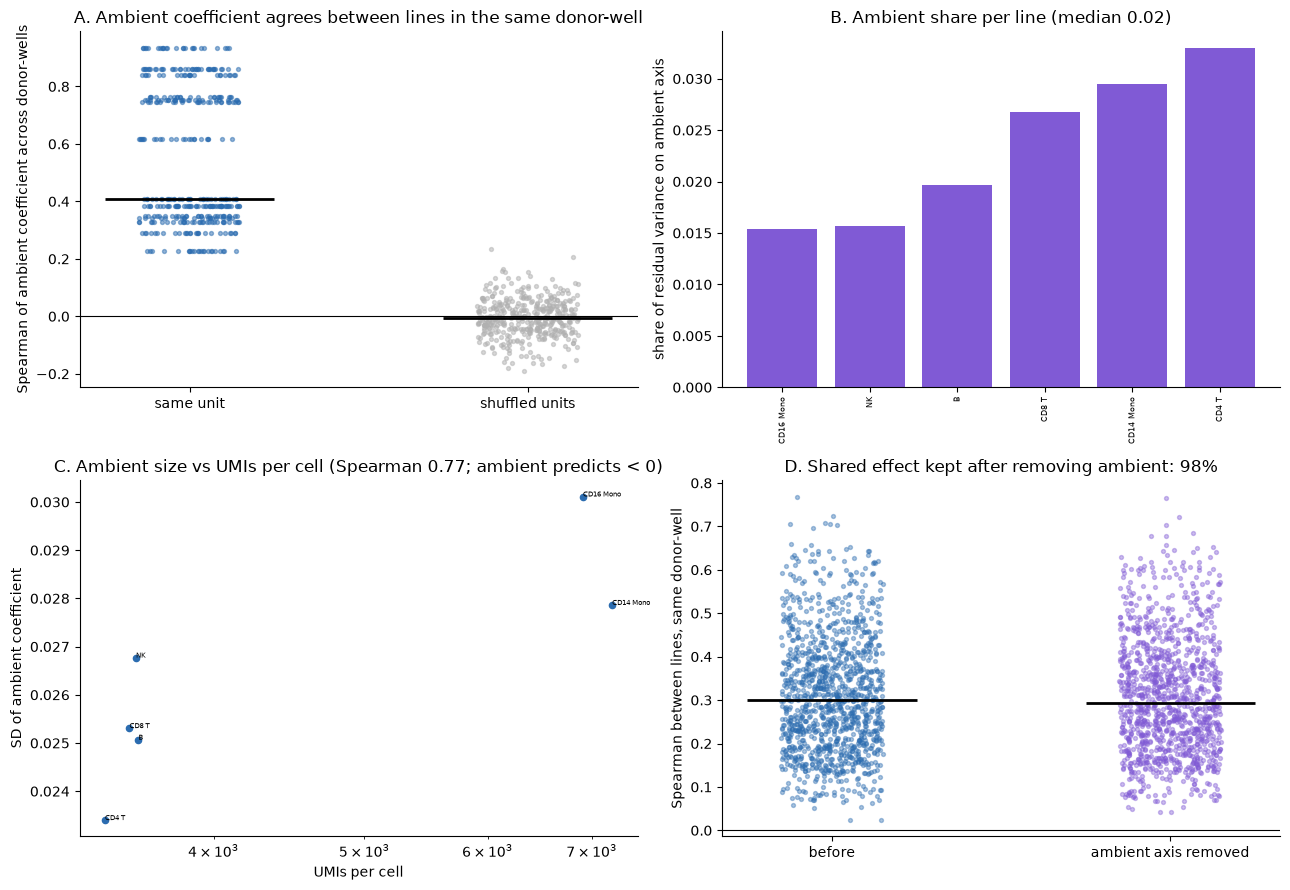

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_parse_shared_well_effect/aim2_parse_ambient_check.png True
                                                          check                     value
                    ambient share of residual variance (median)                     0.023
   ambient coefficient, same unit vs shuffled (median Spearman)           0.408 vs -0.006
same-unit correlation before -> after removing ambient (median) 0.299 -> 0.293 (98% kept)
             Spearman(SD of ambient coefficient, UMIs per cell)                      0.77


In [16]:
t0 = time.time()
beta, share, Xamb = ambient_axis(D, line_cpm, pool_cpm)
cons = beta_consistency(beta)
pairs = sample_pairs(D)
before = same_unit_corrs(D, pairs)
after = same_unit_corrs(remove_ambient(D, beta, Xamb), pairs)
spread = np.nanstd(beta, axis=0)
rho_umi = spearmanr(spread, umi)[0]
print(f"done | {time.time() - t0:.0f}s")

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
a = ax[0, 0]
for i, c in enumerate(cons.columns):
    v = cons[c].dropna().values
    a.scatter(i + rng.uniform(-.15, .15, len(v)), v, s=8, alpha=.5, color=["#2b6cb0", "#b0b0b0"][i])
    a.hlines(np.median(v), i - .25, i + .25, color="k", lw=2)
a.set_xticks([0, 1]); a.set_xticklabels(cons.columns); a.axhline(0, color="k", lw=.8)
a.set_ylabel("Spearman of ambient coefficient across " + UNIT + "s")
a.set_title("A. Ambient coefficient agrees between lines in the same " + UNIT)

a = ax[0, 1]
o_ = np.argsort(share)
a.bar(range(len(share)), share[o_], color="#805ad5")
a.set_xticks(range(len(share))); a.set_xticklabels(np.array(NAMES)[o_], rotation=90, fontsize=6)
a.set_ylabel("share of residual variance on ambient axis")
a.set_title(f"B. Ambient share per line (median {np.median(share):.2f})")

a = ax[1, 0]
a.scatter(umi, spread, s=20, color="#2b6cb0")
for x_, y_, n_ in zip(umi, spread, NAMES):
    a.annotate(n_, (x_, y_), fontsize=5)
a.set_xscale("log"); a.set_xlabel("UMIs per cell"); a.set_ylabel("SD of ambient coefficient")
a.set_title(f"C. Ambient size vs UMIs per cell (Spearman {rho_umi:.2f}; ambient predicts < 0)")

a = ax[1, 1]
for i, (lab, v) in enumerate([("before", before), ("ambient axis removed", after)]):
    a.scatter(i + rng.uniform(-.15, .15, len(v)), v, s=8, alpha=.4, color=["#2b6cb0", "#805ad5"][i])
    a.hlines(np.median(v), i - .25, i + .25, color="k", lw=2)
a.set_xticks([0, 1]); a.set_xticklabels(["before", "ambient axis removed"]); a.axhline(0, color="k", lw=.8)
a.set_ylabel("Spearman between lines, same " + UNIT)
a.set_title(f"D. Shared effect kept after removing ambient: {np.median(after) / np.median(before):.0%}")

for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, f"aim2_{TAG}_ambient_check.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

amb = pd.DataFrame({
    "check": ["ambient share of residual variance (median)",
              "ambient coefficient, same unit vs shuffled (median Spearman)",
              "same-unit correlation before -> after removing ambient (median)",
              "Spearman(SD of ambient coefficient, UMIs per cell)"],
    "value": [f"{np.median(share):.3f}",
              f"{cons['same unit'].median():.3f} vs {cons['shuffled units'].median():.3f}",
              f"{np.median(before):.3f} -> {np.median(after):.3f} ({np.median(after) / np.median(before):.0%} kept)",
              f"{rho_umi:.2f}"]})
amb.to_csv(os.path.join(OUT_DIR, f"aim2_{TAG}_ambient_check.csv"), index=False)
print(amb.to_string(index=False))

done | 2s


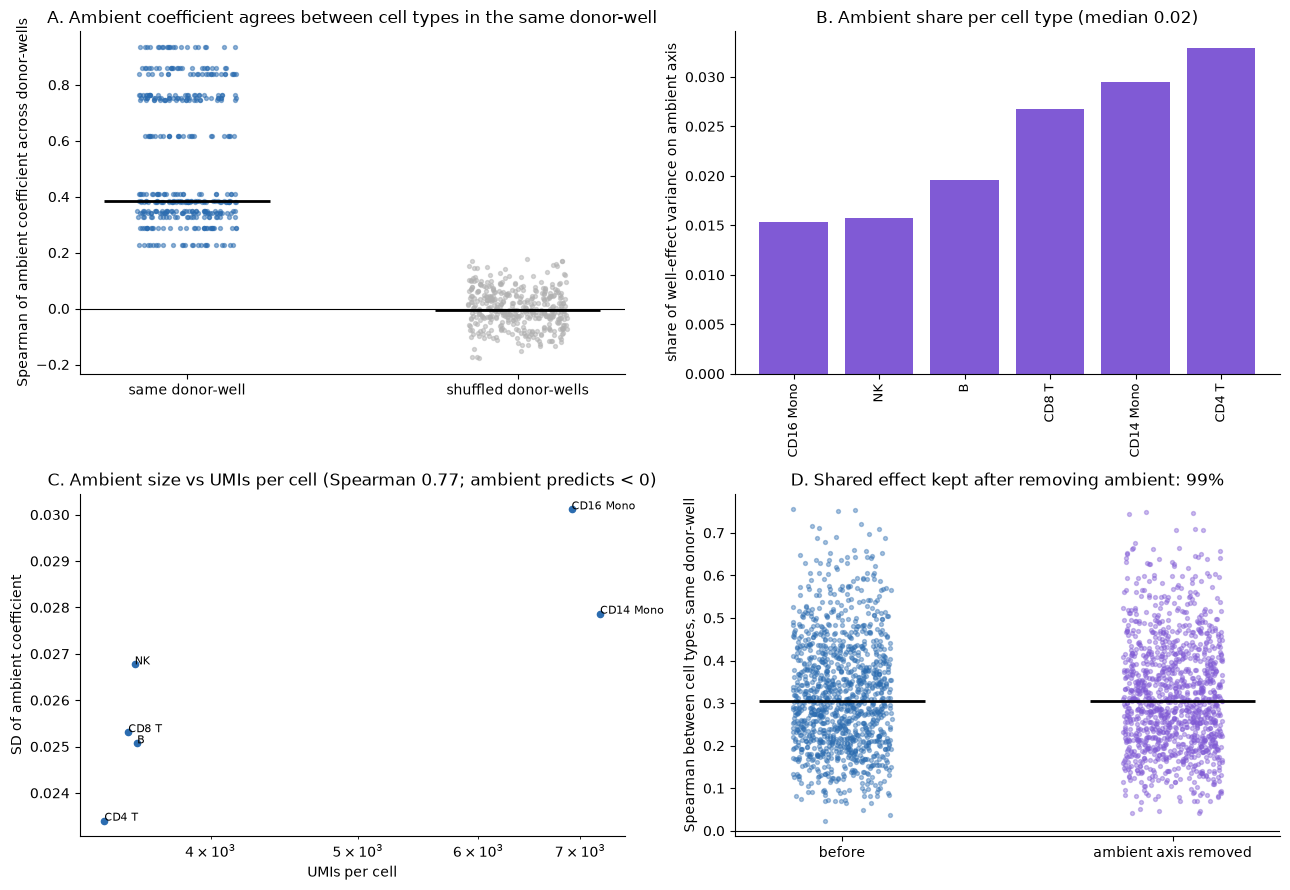

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_parse_shared_well_effect/aim2_parse_ambient_check.png True
                                                          check                     value
                 ambient share of well-effect variance (median)                     0.023
   ambient coefficient, same unit vs shuffled (median Spearman)           0.385 vs -0.005
same-unit correlation before -> after removing ambient (median) 0.306 -> 0.304 (99% kept)
             Spearman(SD of ambient coefficient, UMIs per cell)                      0.77


In [17]:
ITEMS = "cell types" if TAG == "parse" else "cell lines"
ITEM = ITEMS[:-1]

t0 = time.time()
beta, share, Xamb = ambient_axis(D, line_cpm, pool_cpm)
cons = beta_consistency(beta)
pairs = sample_pairs(D)
before = same_unit_corrs(D, pairs)
after = same_unit_corrs(remove_ambient(D, beta, Xamb), pairs)
spread = np.nanstd(beta, axis=0)
rho_umi = spearmanr(spread, umi)[0]
print(f"done | {time.time() - t0:.0f}s")

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
a = ax[0, 0]
for i, c in enumerate(cons.columns):
    v = cons[c].dropna().values
    a.scatter(i + rng.uniform(-.15, .15, len(v)), v, s=8, alpha=.5, color=["#2b6cb0", "#b0b0b0"][i])
    a.hlines(np.median(v), i - .25, i + .25, color="k", lw=2)
a.set_xticks([0, 1]); a.set_xticklabels([f"same {UNIT}", f"shuffled {UNIT}s"]); a.axhline(0, color="k", lw=.8)
a.set_ylabel(f"Spearman of ambient coefficient across {UNIT}s")
a.set_title(f"A. Ambient coefficient agrees between {ITEMS} in the same {UNIT}")

a = ax[0, 1]
o_ = np.argsort(share)
a.bar(range(len(share)), share[o_], color="#805ad5")
a.set_xticks(range(len(share)))
a.set_xticklabels(np.array(NAMES)[o_], rotation=90, fontsize=6 if len(NAMES) > 10 else 9)
a.set_ylabel("share of well-effect variance on ambient axis")
a.set_title(f"B. Ambient share per {ITEM} (median {np.median(share):.2f})")

a = ax[1, 0]
a.scatter(umi, spread, s=20, color="#2b6cb0")
for x_, y_, n_ in zip(umi, spread, NAMES):
    a.annotate(n_, (x_, y_), fontsize=5 if len(NAMES) > 10 else 8)
a.set_xscale("log"); a.set_xlabel("UMIs per cell"); a.set_ylabel("SD of ambient coefficient")
a.set_title(f"C. Ambient size vs UMIs per cell (Spearman {rho_umi:.2f}; ambient predicts < 0)")

a = ax[1, 1]
for i, v in enumerate([before, after]):
    a.scatter(i + rng.uniform(-.15, .15, len(v)), v, s=8, alpha=.4, color=["#2b6cb0", "#805ad5"][i])
    a.hlines(np.median(v), i - .25, i + .25, color="k", lw=2)
a.set_xticks([0, 1]); a.set_xticklabels(["before", "ambient axis removed"]); a.axhline(0, color="k", lw=.8)
a.set_ylabel(f"Spearman between {ITEMS}, same {UNIT}")
a.set_title(f"D. Shared effect kept after removing ambient: {np.median(after) / np.median(before):.0%}")

for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, f"aim2_{TAG}_ambient_check.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

amb = pd.DataFrame({
    "check": ["ambient share of well-effect variance (median)",
              "ambient coefficient, same unit vs shuffled (median Spearman)",
              "same-unit correlation before -> after removing ambient (median)",
              "Spearman(SD of ambient coefficient, UMIs per cell)"],
    "value": [f"{np.median(share):.3f}",
              f"{cons['same unit'].median():.3f} vs {cons['shuffled units'].median():.3f}",
              f"{np.median(before):.3f} -> {np.median(after):.3f} ({np.median(after) / np.median(before):.0%} kept)",
              f"{rho_umi:.2f}"]})
amb.to_csv(os.path.join(OUT_DIR, f"aim2_{TAG}_ambient_check.csv"), index=False)
print(amb.to_string(index=False))

In [18]:
# Section 11 of aim2_parse_shared_well_effect.ipynb: is the shared well effect made by doublets?
# In split-pool barcoding, two cells can only share all barcodes if they were in the same first-round well, so
# doublets and barcode collisions stay inside a well. A doublet of a T cell and a monocyte that is labelled as a T cell
# carries monocyte transcripts into the T-cell pseudobulk of that well, which would create a signal shared by the cell
# types of the well. Two kinds of doublet candidates are removed:
#   (1) mixed identity: the share of a cell's transcripts from marker genes of a lineage other than its own is in the
#       top 5% of its cell type (T: CD3D/E/G; B: MS4A1, CD79A/B; monocytes: LYZ, S100A8/9, CST3; NK: GNLY, NKG7, KLRD1;
#       for CD8 T and NK cells, NK and T markers are not counted as foreign, since these lineages share them);
#   (2) high transcript count: above twice the median of the cell's (donor, well, cell type).
# Three pseudobulks are built from the same cells: all cells, without the candidates ("clean"), candidates only.
# Tests A (PBS vs PBS, same vs disjoint well pairs) and B (inert residuals, same vs different well) are repeated on
# each, with the definitions of sections 4 and 5 and the same genes.
# Fixed before running: doublets do not explain the shared signal if, without the candidates, the same-well excess
# (same minus different) keeps at least 80% of its value with all cells in both tests.
# Run after section 3 (uses DATA_PATH, CHUNK, MIN_CELLS, CELL_TYPES, genes, donors, PBS_WELLS, INERT_WELLS, rng).
# Two passes over the 10M cells (about twice the time of section 2).
import time
t0 = time.time()
DB_DIR = os.path.join(OUT_DIR, "doublets"); os.makedirs(DB_DIR, exist_ok=True)
FOREIGN_Q = 0.95
UMI_FOLD = 2.0
LINEAGE = {"T": ["CD3D", "CD3E", "CD3G"], "B": ["MS4A1", "CD79A", "CD79B"],
           "Mono": ["LYZ", "S100A8", "S100A9", "CST3"], "NK": ["GNLY", "NKG7", "KLRD1"]}
OWN = {"CD4 T": {"T"}, "CD8 T": {"T", "NK"}, "B": {"B"}, "CD14 Mono": {"Mono"}, "CD16 Mono": {"Mono"}, "NK": {"NK", "T"}}
CACHE_CELLS = os.path.join(DB_DIR, "cell_scores.npz")

a = ad.read_h5ad(DATA_PATH, backed="r")
ob = a.obs[["donor", "bc1_well", "cell_type"]].astype(str).copy()
ob["ct"] = ob.cell_type.map(lambda x: to_coarse(x))
vn = pd.Index(a.var_names.astype(str))
mk = {lin: [vn.get_loc(g) for g in gl if g in vn] for lin, gl in LINEAGE.items()}
print("Marker genes found:", {k: len(v) for k, v in mk.items()})
ct_codes = ob.ct.map({c: i for i, c in enumerate(CELL_TYPES)}).fillna(-1).astype(int).values

# ---- pass 1: transcripts per cell and share from foreign lineage markers
if os.path.exists(CACHE_CELLS):
    z = np.load(CACHE_CELLS); umi, foreign = z["umi"], z["foreign"]; print("Loaded cell scores")
else:
    umi = np.zeros(a.n_obs, np.float32); foreign = np.zeros(a.n_obs, np.float32)
    lin_names = list(LINEAGE)
    for s in range(0, a.n_obs, CHUNK):
        e = min(s + CHUNK, a.n_obs)
        X = a.X[s:e]; X = X if sp.issparse(X) else sp.csr_matrix(X)
        umi[s:e] = np.asarray(X.sum(1)).ravel()
        lin_sum = np.column_stack([np.asarray(X[:, mk[l]].sum(1)).ravel() if mk[l] else np.zeros(e - s) for l in lin_names])
        cc = ct_codes[s:e]
        for i, c in enumerate(CELL_TYPES):
            m = cc == i
            if m.any():
                fl = [j for j, l in enumerate(lin_names) if l not in OWN[c]]
                foreign[s:e][m] = lin_sum[m][:, fl].sum(1) / np.maximum(umi[s:e][m], 1)
        if (s // CHUNK) % 10 == 0 or e == a.n_obs:
            el = time.time() - t0
            print(f"  pass 1: {e / a.n_obs:.0%} | {el / 60:.1f} min | remaining ~{el / e * (a.n_obs - e) / 60:.0f} min", flush=True)
    np.savez(CACHE_CELLS, umi=umi, foreign=foreign)

ok_cell = ct_codes >= 0
thr_f = pd.Series(foreign[ok_cell]).groupby(ct_codes[ok_cell]).quantile(FOREIGN_Q)
mixed = ok_cell & (foreign > thr_f.reindex(ct_codes).values)
key = (ob.donor + "|" + ob.bc1_well + "|" + ob.ct.fillna("NA")).where(ob.ct.notna())
med = pd.Series(umi).groupby(key.values).transform("median").values
high = ok_cell & (umi > UMI_FOLD * med)
cand = mixed | high
print(f"Doublet candidates among kept cells: mixed identity {mixed[ok_cell].mean():.1%}, "
      f"high count {high[ok_cell].mean():.1%}, either {cand[ok_cell].mean():.1%}")
print(pd.Series(cand[ok_cell]).groupby(ob.ct.values[ok_cell]).mean().round(3).to_dict())

# ---- pass 2: pseudobulks on the genes of section 3, for single cells and candidates separately
PB2 = os.path.join(DB_DIR, "pb_doublet_split.npz")
codes, groups = pd.factorize(key)
if os.path.exists(PB2):
    z = np.load(PB2, allow_pickle=True)
    acc0, acc1, n0, n1, lib0, lib1, groups = z["acc0"], z["acc1"], z["n0"], z["n1"], z["lib0"], z["lib1"], z["groups"]
    print("Loaded pseudobulks")
else:
    G_IDX = np.asarray(genes)                     # only the genes of section 3; library sizes kept separately
    acc0 = np.zeros((len(groups), len(G_IDX)), np.float32); acc1 = np.zeros_like(acc0)
    for s in range(0, a.n_obs, CHUNK):
        e = min(s + CHUNK, a.n_obs)
        X = a.X[s:e]; X = X if sp.issparse(X) else sp.csr_matrix(X)
        c = codes[s:e]
        for acc, m in [(acc0, (c >= 0) & ~cand[s:e]), (acc1, (c >= 0) & cand[s:e])]:
            idx_ = np.where(m)[0]
            if len(idx_):
                ug, local = np.unique(c[idx_], return_inverse=True)
                Gm = sp.csr_matrix((np.ones(len(local), np.float32), (local, np.arange(len(local)))), shape=(len(ug), len(local)))
                acc[ug] += np.asarray((Gm @ X[idx_][:, G_IDX]).todense(), dtype=np.float32)
        if (s // CHUNK) % 10 == 0 or e == a.n_obs:
            el = time.time() - t0
            print(f"  pass 2: {e / a.n_obs:.0%} | {el / 60:.1f} min", flush=True)
    lib0 = np.bincount(codes[(codes >= 0) & ~cand], weights=umi[(codes >= 0) & ~cand], minlength=len(groups))
    lib1 = np.bincount(codes[(codes >= 0) & cand], weights=umi[(codes >= 0) & cand], minlength=len(groups))
    n0 = np.bincount(codes[(codes >= 0) & ~cand], minlength=len(groups))
    n1 = np.bincount(codes[(codes >= 0) & cand], minlength=len(groups))
    np.savez(PB2, acc0=acc0, acc1=acc1, n0=n0, n1=n1, lib0=lib0, lib1=lib1, groups=np.array(groups, dtype=object))
a.file.close()
stamp_ = lambda w: print(f"[{w}] {(time.time() - t0) / 60:.1f} min")
stamp_("doublet pseudobulks")

# ---- tests A and B on each version (same genes as section 3)
gmeta = pd.DataFrame([g.split("|") for g in groups], columns=["donor", "well", "ct"])


def make_vec(acc, lib, n, min_cells):
    Lv = np.log2(acc / np.maximum(lib, 1)[:, None] * 1e6 + 1).astype(np.float32)   # CPM on the full library
    d_ = {}
    for i, (d, w, c) in enumerate(zip(gmeta.donor, gmeta.well, gmeta.ct)):
        if n[i] >= min_cells:
            d_[(d, w, c)] = Lv[i]
    return d_


def tests(V):
    rr = np.random.default_rng(SEED)
    A_same, A_dis = [], []
    for d in donors:
        W = PBS_WELLS[d]
        pairs = [(W[i], W[j]) for i in range(len(W)) for j in range(i + 1, len(W))]
        diff = {(p, c): V[(d, p[0], c)] - V[(d, p[1], c)] for p in pairs for c in CELL_TYPES
                if (d, p[0], c) in V and (d, p[1], c) in V}
        s_, d_ = [], []
        for c1, c2 in CT_PAIRS:
            for p in pairs:
                if (p, c1) in diff and (p, c2) in diff:
                    s_.append(spear(diff[(p, c1)], diff[(p, c2)]))
                for q in pairs:
                    if set(p) & set(q) or q <= p:
                        continue
                    if (p, c1) in diff and (q, c2) in diff:
                        d_.append(spear(diff[(p, c1)], diff[(q, c2)]))
        if s_: A_same.append(np.median(s_))
        if d_: A_dis.append(np.median(d_))
    B_same, B_dif = [], []
    for d in donors:
        R = {}
        for c in CELL_TYPES:
            W = [w for w in INERT_WELLS[d] if (d, w, c) in V]
            if len(W) >= 4:
                M = np.vstack([V[(d, w, c)] for w in W]); R[c] = dict(zip(W, M - M.mean(0)))
        s_, f_ = [], []
        for c1, c2 in CT_PAIRS:
            if c1 not in R or c2 not in R:
                continue
            common = sorted(set(R[c1]) & set(R[c2]))
            for w in common:
                s_.append(spear(R[c1][w], R[c2][w]))
                others = [x for x in common if x != w]
                for w2 in rr.choice(others, size=min(3, len(others)), replace=False):
                    f_.append(spear(R[c1][w], R[c2][w2]))
        if s_: B_same.append(np.median(s_))
        if f_: B_dif.append(np.median(f_))
    return dict(testA_same=np.median(A_same), testA_disjoint=np.median(A_dis), testB_same=np.median(B_same),
                testB_different=np.median(B_dif))


rows = []
for name, acc, lib, n, mc in [("all", acc0 + acc1, lib0 + lib1, n0 + n1, MIN_CELLS), ("clean", acc0, lib0, n0, MIN_CELLS),
                              ("candidates", acc1, lib1, n1, 10)]:
    r = tests(make_vec(acc, lib, n, mc)); r["version"] = name
    r["testA_excess"] = r["testA_same"] - r["testA_disjoint"]; r["testB_excess"] = r["testB_same"] - r["testB_different"]
    rows.append(r)
DBLP = pd.DataFrame(rows).set_index("version")
DBLP.to_csv(os.path.join(DB_DIR, "doublet_tests_parse.csv"))
print(DBLP.round(3).to_string())
kA = DBLP.loc["clean", "testA_excess"] / DBLP.loc["all", "testA_excess"]
kB = DBLP.loc["clean", "testB_excess"] / DBLP.loc["all", "testB_excess"]
print(f"\nExcess kept without doublet candidates: Test A {kA:.0%}, Test B {kB:.0%}")
print(f"Fixed rule (>= 80% in both): doublets do not explain the shared signal: {bool(kA >= 0.8 and kB >= 0.8)}")
stamp_("doublet tests")

Marker genes found: {'T': 3, 'B': 3, 'Mono': 4, 'NK': 3}
  pass 1: 2% | 0.4 min | remaining ~20 min
  pass 1: 23% | 2.3 min | remaining ~8 min
  pass 1: 43% | 4.2 min | remaining ~5 min
  pass 1: 64% | 6.0 min | remaining ~3 min
  pass 1: 85% | 7.9 min | remaining ~1 min
  pass 1: 100% | 9.3 min | remaining ~0 min
Doublet candidates among kept cells: mixed identity 5.0%, high count 12.0%, either 16.7%
{'B': 0.184, 'CD14 Mono': 0.18, 'CD16 Mono': 0.171, 'CD4 T': 0.164, 'CD8 T': 0.152, 'NK': 0.154}
  pass 2: 2% | 9.6 min
  pass 2: 23% | 11.6 min
  pass 2: 43% | 13.6 min
  pass 2: 64% | 15.8 min
  pass 2: 85% | 17.7 min
  pass 2: 100% | 19.2 min
[doublet pseudobulks] 19.3 min
            testA_same  testA_disjoint  testB_same  testB_different  testA_excess  testB_excess
version                                                                                        
all              0.403           0.016       0.386           -0.028         0.387         0.414
clean            0.372        